In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from sklearn.metrics import ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset

# PARAMETRI

In [2]:
EPOCHS = 100
BATCH_SIZE = 128
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


In [3]:
from datasets.datasets import load_IMDB

# DATASET: 50.000 recensioni di film (IMDB), 25.000 di training e 25.000 di test, metà positive e metà negative.
# Ogni recensione è una sequenza di indici di parole ordinate per frequenza (0 = padding, 1 = inizio, 2 = parola rara)
NUM_WORDS = 10000     # si tengono solo le parole più frequenti: le altre diventano 2
MAXLEN = 500          # le recensioni vengono troncate, o completate con zeri all'inizio, fino a MAXLEN parole

(x_train, y_train), (x_test, y_test) = load_IMDB(num_words=NUM_WORDS, maxlen=MAXLEN)
print(f"SHAPE: X_TRAIN = {x_train.shape}, Y_TRAIN = {y_train.shape}")
print(f"SHAPE: X_TEST = {x_test.shape}, Y_TEST = {y_test.shape}")
print(f"RECENSIONI POSITIVE (train): {y_train.mean():.0%}\n")
print(x_train[0])

train_dataset = TensorDataset(torch.tensor(x_train), torch.tensor(y_train))
test_dataset = TensorDataset(torch.tensor(x_test), torch.tensor(y_test))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

SHAPE: X_TRAIN = (25000, 500), Y_TRAIN = (25000,)
SHAPE: X_TEST = (25000, 500), Y_TEST = (25000,)
RECENSIONI POSITIVE (train): 50%

[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0 

# MODELLO

In [4]:
#Parametri del modello
EMBEDDING_DIM = 32
HIDDEN_SIZE = 32
NUM_CLASSES = 2                   # negativa, positiva

In [5]:
# nn.RNN, nn.LSTM e nn.GRU restituiscono (output, stato), quindi non si possono mettere direttamente in un nn.Sequential
class RNNClassifier(nn.Module):
    def __init__(self, num_words, embedding_dim, hidden_size, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(num_words, embedding_dim)   # ogni indice di parola -> vettore da embedding_dim valori
        self.rnn = nn.RNN(embedding_dim, hidden_size, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):                          # (B, 500) indici delle parole
        x = self.embedding(x)                      # (B, 500, EMBEDDING_DIM): 500 passi da 32 valori
        out, _ = self.rnn(x)                       # (B, 500, HIDDEN_SIZE)
        return self.fc(out[:, -1])                 # uscita dell'ultimo passo -> logit (B, NUM_CLASSES)

torch.manual_seed(7)
model = RNNClassifier(NUM_WORDS, EMBEDDING_DIM, HIDDEN_SIZE, NUM_CLASSES).to(DEVICE)

# RMSprop mantiene una media mobile dei quadrati dei gradienti e divide il gradiente per la sua radice.
optimizer = torch.optim.RMSprop(model.parameters(), lr=LEARNING_RATE, alpha=0.9, eps=1e-7)
# Due logit + CrossEntropyLoss equivalgono a un logit + sigmoide + binary cross-entropy, e l'accuracy si calcola con argmax
criterion = nn.CrossEntropyLoss()

print(model)
print(f"Parametri: {sum(p.numel() for p in model.parameters())}")   # 322178 e non 322113: nn.RNN ha due vettori di bias e il Linear 2 uscite

RNNClassifier(
  (embedding): Embedding(10000, 32)
  (rnn): RNN(32, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=2, bias=True)
)
Parametri: 322178


# ADDESTRAMENTO

  0%|          | 0/100 [00:00<?, ?it/s]

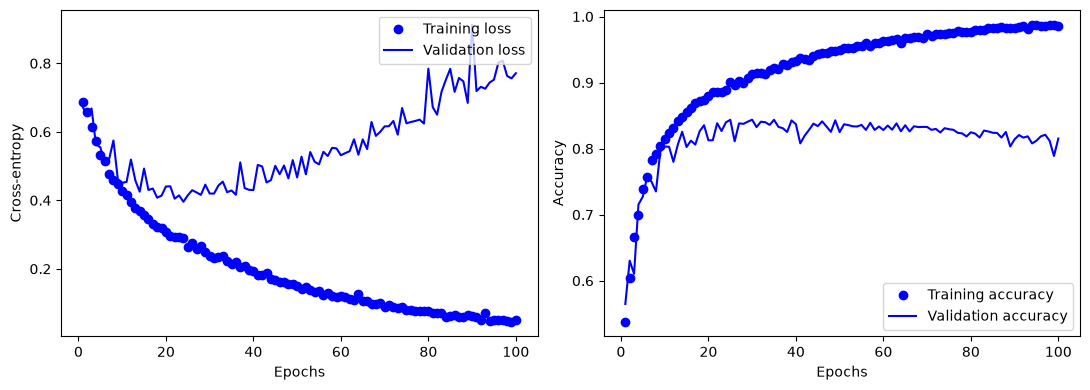

In [6]:
os.makedirs('histories', exist_ok=True)
filename = f"text_classifier"   # file diversi per celle e dimensioni diverse

hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'
if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history = pickle.load(hist_file)
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history = utils.train(model, optimizer, criterion, train_loader, test_loader, EPOCHS, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history, hist_file)
    torch.save(model.state_dict(), weights_path)

epochs = range(1, len(history['loss']) + 1)
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history['loss'], 'bo', label='Training loss')
plt.plot(epochs, history['val_loss'], 'b', label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Cross-entropy')
plt.legend(loc='upper right')
plt.subplot(1, 2, 2)
plt.plot(epochs, history['accuracy'], 'bo', label='Training accuracy')
plt.plot(epochs, history['val_accuracy'], 'b', label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# VALUTAZIONE

accuracy train = 0.992   accuracy test = 0.815


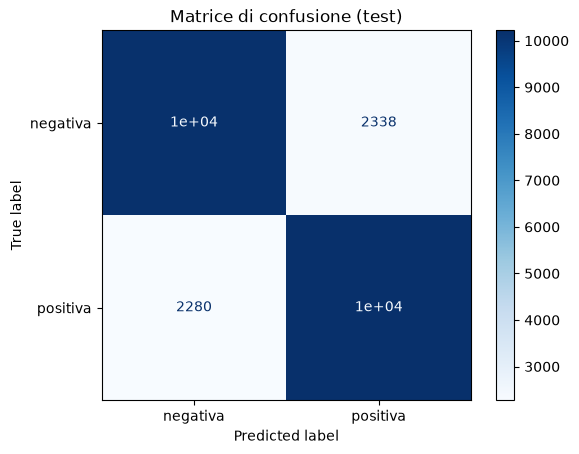

In [7]:
def predict(model, dataset, batch_size=1024):
    # a blocchi: 25.000 recensioni x 500 passi x 32 valori tutte insieme non entrano in memoria
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in DataLoader(dataset, batch_size=batch_size, shuffle=False):
            preds.append(model(x.to(DEVICE)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

y_train_pred = predict(model, train_dataset)
y_test_pred = predict(model, test_dataset)
print(f"accuracy train = {np.mean(y_train_pred == y_train):.3f}   accuracy test = {np.mean(y_test_pred == y_test):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=['negativa', 'positiva'], cmap='Blues')
plt.title(f'Matrice di confusione (test)')
plt.show()